# SNEAK: LongMemEval-V2 bounded diagnostic

**This is not the official LongMemEval-V2 benchmark.** Two questions from the official question set, no trajectory retrieval, and two local Ollama models. Security bonus score remains NULL while SCA is unverified.

In [1]:
from pathlib import Path
import json, hashlib, sys
root=Path.cwd()
sys.path.insert(0,str(root/'src'))
from sneak.fcg_registry import FCGRegistry
p=root/'receipts/evaluations/LMEV2_20261020_PILOT.json'
receipt=json.loads(p.read_text())
sha=hashlib.sha256(p.read_bytes()).hexdigest()
print('Receipt SHA-256:', sha)
assert sha == '8f65c60c626e784300e615bc0e6babb15bf6f172a2ba1430f8401f6f1cb68985'

Receipt SHA-256: 8f65c60c626e784300e615bc0e6babb15bf6f172a2ba1430f8401f6f1cb68985


## Source and chain verification

Hashes establish byte identity, not accuracy or security. The pilot root must be an exact ledger prefix; new later FCOs may exist.

In [2]:
from sneak.fcg_registry import verify_rows
ledger=root/'data/fcg/sneak-016-replay.jsonl'
rows=[json.loads(s) for s in ledger.read_text().splitlines() if s.strip()]
prefix=verify_rows(rows[:74])
assert prefix['mmr_root'] == receipt['successor_mmr']['mmr_root']
assert receipt['parent_mmr']['fco_count'] == 58
print('Pilot MMR prefix:', prefix)
print('Latest verified ledger:', FCGRegistry(ledger).verify())

Pilot MMR prefix: {'verified': True, 'fco_count': 74, 'mmr_size': 145, 'mmr_root': '713334f89e48d44ea64b00651dfc1cf577e9aaab1e4b1d7be71d310f3e033f20', 'fcg_edges': 82}
Latest verified ledger: {'verified': True, 'fco_count': 74, 'mmr_size': 145, 'mmr_root': '713334f89e48d44ea64b00651dfc1cf577e9aaab1e4b1d7be71d310f3e033f20', 'fcg_edges': 82}


## Question-level outcomes

The official deterministic rule evaluator was used for this bounded pilot. Model output was not supplied with gold answers. Accuracy is the fraction correct of only two questions.

In [3]:
for method in receipt['results']:
    print(method['model'], '|', method['questions_scored'], 'scored | accuracy=', method['diagnostic_accuracy'])
    for question in method['question_results']:
        print('   ', question['domain'], question['question_id'], 'correct=', question['correct'], 'latency_ms=', question['latency_ms'])

qwen3:1.7b | 2 scored | accuracy= 0.0
    enterprise 01307e07 correct= False latency_ms= 16437.27
    web 00aa905a correct= False latency_ms= 1314.28
hf.co/LiquidAI/LFM2.5-1.2B-Instruct-GGUF:latest | 2 scored | accuracy= 0.5
    enterprise 01307e07 correct= False latency_ms= 6488.26
    web 00aa905a correct= True latency_ms= 812.89


## Diagnostic model comparison

This is not a LongMemEval-V2 leaderboard result and is not memory-system improvement.

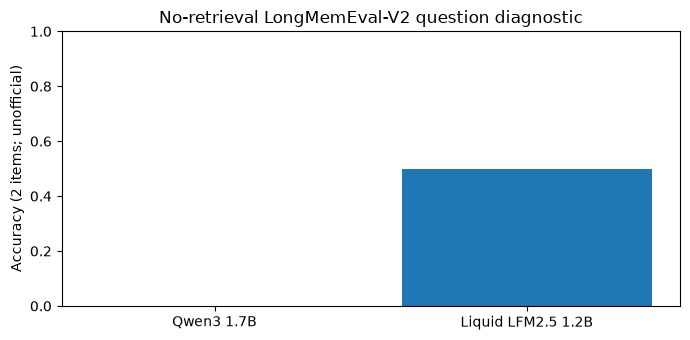

In [4]:
import matplotlib.pyplot as plt
labels=['Qwen3 1.7B','Liquid LFM2.5 1.2B']
accuracy=[x['diagnostic_accuracy'] for x in receipt['results']]
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(labels, accuracy)
ax.set_ylim(0,1)
ax.set_ylabel('Accuracy (2 items; unofficial)')
ax.set_title('No-retrieval LongMemEval-V2 question diagnostic')
plt.tight_layout()
plt.show()

## Provider and security gates

BAND/Cognee were unavailable on this execution host. The Snyk Code scan returned five low findings, but the Open Source stage is incomplete, so the accepted Javier application score is NULL. No official LAFS gain is computed.

In [5]:
for r in receipt['results']:
    print(r['model'], '| Cognee:', r['cognee'], '| BAND:', r['band'])
assert all(r['band']=='NOT_TESTED' and r['cognee']=='NOT_TESTED' for r in receipt['results'])
assert receipt['security_admission']=='DENY'
assert receipt['official_full_benchmark']=='NOT_TESTED'
print('PASS: unsupported claims remain blocked')

qwen3:1.7b | Cognee: NOT_TESTED | BAND: NOT_TESTED
hf.co/LiquidAI/LFM2.5-1.2B-Instruct-GGUF:latest | Cognee: NOT_TESTED | BAND: NOT_TESTED
PASS: unsupported claims remain blocked
